In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

PROJECT_ROOT = Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "daily_features.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nUnique Participants:", df["Id"].nunique())

Dataset Shape: (199, 21)

Columns:
['Id', 'date', 'TotalSteps', 'Calories', 'VeryActiveMinutes', 'FairlyActiveMinutes', 'LightlyActiveMinutes', 'SedentaryMinutes', 'recorded_sleep_minutes', 'baseline_steps_7d', 'baseline_sleep_7d', 'steps_deviation_7d', 'steps_deviation_7d_pct', 'sleep_deviation_7d', 'sleep_deviation_7d_pct', 'steps_rolling_3d', 'sleep_rolling_3d', 'activity_ratio', 'sleep_ratio', 'day_number', 'is_baseline']

Missing Values:
Id                        0
date                      0
TotalSteps                0
Calories                  0
VeryActiveMinutes         0
FairlyActiveMinutes       0
LightlyActiveMinutes      0
SedentaryMinutes          0
recorded_sleep_minutes    0
baseline_steps_7d         0
baseline_sleep_7d         0
steps_deviation_7d        0
steps_deviation_7d_pct    0
sleep_deviation_7d        0
sleep_deviation_7d_pct    0
steps_rolling_3d          0
sleep_rolling_3d          0
activity_ratio            0
sleep_ratio               0
day_number           

In [2]:
participant_summary = (
    df.groupby("Id")
    .agg(
        observations=("date", "count"),
        first_date=("date", "min"),
        last_date=("date", "max"),
        avg_steps=("TotalSteps", "mean"),
        avg_sleep=("recorded_sleep_minutes", "mean")
    )
    .reset_index()
)

participant_summary = participant_summary.sort_values(
    by="observations",
    ascending=False
)

participant_summary

,Id,observations,first_date,last_date,avg_steps,avg_sleep
6,4020332650,15,2016-03-12,2016-04-11,5982.200000,406.733333
0,1503960366,14,2016-03-25,2016-04-11,12520.214286,411.071429
4,2347167796,14,2016-03-29,2016-04-11,10500.071429,474.357143
10,4702921684,14,2016-03-29,2016-04-11,8510.785714,509.642857
15,6962181067,14,2016-03-30,2016-04-12,12639.714286,471.357143
11,5553957443,12,2016-04-01,2016-04-12,8354.750000,585.000000
3,2026352035,12,2016-04-01,2016-04-12,3392.750000,593.750000
8,4445114986,12,2016-03-29,2016-04-12,4685.666667,429.333333
18,8378563200,12,2016-04-01,2016-04-12,8135.250000,488.416667
5,3977333714,11,2016-04-01,2016-04-11,9382.545455,557.818182


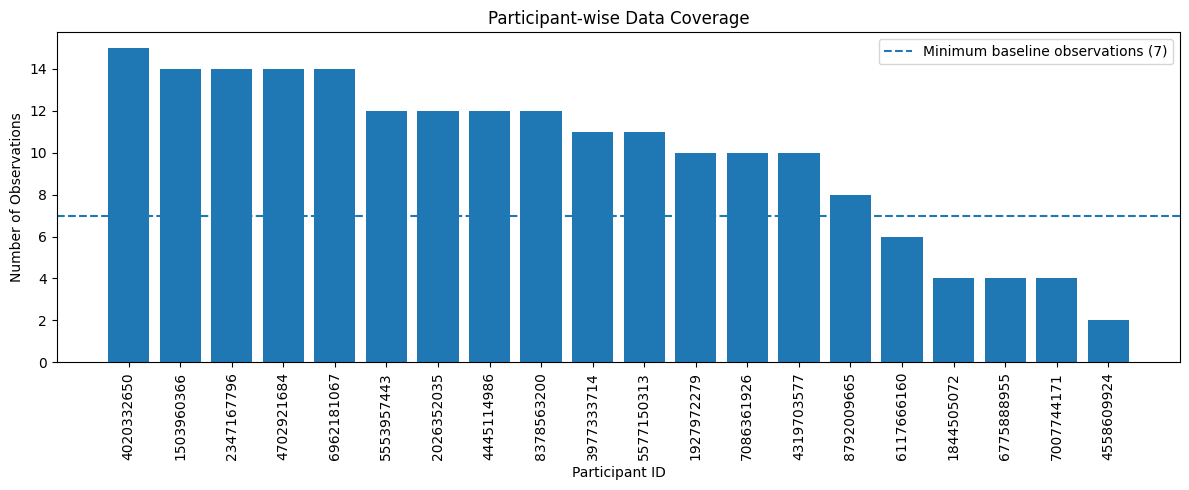

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.bar(
    participant_summary["Id"].astype(str),
    participant_summary["observations"]
)

plt.axhline(
    y=7,
    linestyle="--",
    label="Minimum baseline observations (7)"
)

plt.xticks(rotation=90)
plt.xlabel("Participant ID")
plt.ylabel("Number of Observations")
plt.title("Participant-wise Data Coverage")
plt.legend()
plt.tight_layout()
plt.show()

In [4]:
total_participants = df["Id"].nunique()

eligible = participant_summary[
    participant_summary["observations"] >= 8
]

limited = participant_summary[
    participant_summary["observations"] < 8
]

print("Total participants:", total_participants)
print("Eligible participants:", len(eligible))
print("Limited coverage:", len(limited))

print(
    "Eligible coverage percentage:",
    round(len(eligible) / total_participants * 100, 2),
    "%"
)

print("\nParticipants with limited coverage:")
print(limited[["Id", "observations"]].to_string(index=False))

Total participants: 20
Eligible participants: 15
Limited coverage: 5
Eligible coverage percentage: 75.0 %

Participants with limited coverage:
        Id  observations
6117666160             6
1844505072             4
6775888955             4
7007744171             4
4558609924             2


In [5]:
eligible_ids = eligible["Id"].tolist()

df_eligible = df[
    df["Id"].isin(eligible_ids)
].copy()

print("Original dataset:", df.shape)
print("Eligible dataset:", df_eligible.shape)
print("Eligible participants:", df_eligible["Id"].nunique())

print("\nBaseline distribution:")
print(df_eligible["is_baseline"].value_counts())

Original dataset: (199, 21)
Eligible dataset: (179, 21)
Eligible participants: 15

Baseline distribution:
is_baseline
True     105
False     74
Name: count, dtype: int64


In [6]:
df_eligible["date"] = pd.to_datetime(df_eligible["date"])

print("Duplicate participant-date records:",
      df_eligible.duplicated(subset=["Id", "date"]).sum())

print("\nBaseline count per participant:")
print(
    df_eligible.groupby("Id")["is_baseline"]
    .sum()
    .value_counts()
    .sort_index()
)

print("\nObservation count per participant:")
print(
    df_eligible.groupby("Id")["day_number"]
    .max()
    .describe()
)

print("\nDate range:")
print(df_eligible["date"].min(), "to", df_eligible["date"].max())

Duplicate participant-date records: 0

Baseline count per participant:
is_baseline
7    15
Name: count, dtype: int64

Observation count per participant:
count    15.000000
mean     11.933333
std       1.980861
min       8.000000
25%      10.500000
50%      12.000000
75%      14.000000
max      15.000000
Name: day_number, dtype: float64

Date range:
2016-03-12 00:00:00 to 2016-04-12 00:00:00


## Day 20 — ML Foundation Review: Research Conclusion

### 1. Dataset Integrity
The processed wearable dataset contains 199 records across 20 participants and 21 features. No missing values or exact duplicate records were identified during the initial diagnostics.

### 2. Participant Eligibility
A minimum of eight observations was selected as the eligibility criterion: seven observations to establish a personal baseline and at least one subsequent observation for evaluation.

- Total participants: 20
- Eligible participants: 15 (75%)
- Participants with limited coverage: 5 (25%)
- Eligible records: 179
- Baseline records: 105
- Post-baseline records: 74

### 3. Temporal Integrity
No duplicate participant-date records were found. All 15 eligible participants had exactly seven baseline observations. Their observation counts ranged from 8 to 15, with a median of 12.

### 4. Research Limitations
- The dataset contains a small number of participants.
- Participant observation counts are uneven.
- Recorded sleep duration may reflect incomplete wearable recording.
- The dataset does not provide clinical ground-truth labels.
- Anomaly detection results must not be interpreted as medical diagnoses.
- The dataset is historical and may not represent current populations or wearable devices.

### 5. ML Foundation Decision
Isolation Forest will remain the candidate anomaly-detection model for the MVP, subject to appropriate evaluation and transparent limitations. The PyTorch time-series experiment will remain a research experiment because target scaling did not produce a meaningful overall improvement over the mean-prediction baseline.

### 6. Conclusion
The dataset has passed the structural and temporal checks performed in this review. The eligible subset provides a consistent foundation for further exploratory personalized wearable-pattern analysis. These findings do not establish clinical validity.

**Next phase:** Integrate the ML foundation into the multi-department Health-AI application, beginning with database and backend architecture.